<a href="https://colab.research.google.com/github/valegio/era5_correction_high_andes/blob/main/scripts/1_data_cleaning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In this notebook 6 datasets are cleaned:

1) **era5_daily_putre_caspana_basins.csv**: ERA5-Land data for Putre and Caspana basins (aggregated by basin)
2) **era5_daily_putre_caspana_stations.csv**: ERA5-Land data for Putre and Caspana stations (pixel sample)
3) **tmean_cr2met_C_day.csv**: CAMELS temperature data for Putre and Caspana basins
4) **precip_cr2met_mm_day**: CAMELS precipitation data for Putre and Caspana basins
5) **inia_caspana_20261115**: INIA data for Caspana station
6) **inia_putre_2026111**: INIA data for Putre station


In [1]:
# Mount Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
# ---------------------------------------------------------
# Set Working directory
# ---------------------------------------------------------
# Build the path
project_folder <- "era5_correction_high_andes"
project_path <- file.path("/content/drive/MyDrive", project_folder)

# Set the working directory
setwd(project_path)

# Confirm
getwd()


[1] "/content/drive/MyDrive/era5_correction_high_andes"

In [2]:
# ---------------------------------------------------------
# Load packages
# ---------------------------------------------------------
library(readr)   # read_csv / write_csv
library(dplyr)   # data manipulation
library(ggplot2) # plot
library(tidyr)



Attaching package: ‘dplyr’


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union




## Load ERA5-Land data

Aggregated by basin:

In [19]:
# ---------------------------------------------------------
# Read and inspect ERA-5 Land data
# ---------------------------------------------------------
# Read raw data
df_raw_b <- read_csv("raw_data/era5_daily_putre_caspana_basins.csv")

# Show first rows
head(df_raw_b)

Rows: 56140 Columns: 154
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (3): system:index, site, .geo
dbl  (150): dewpoint_temperature_2m, dewpoint_temperature_2m_max, dewpoint_t...
date   (1): date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


system:index,date,dewpoint_temperature_2m,dewpoint_temperature_2m_max,dewpoint_temperature_2m_min,evaporation_from_bare_soil_max,evaporation_from_bare_soil_min,evaporation_from_bare_soil_sum,evaporation_from_open_water_surfaces_excluding_oceans_max,evaporation_from_open_water_surfaces_excluding_oceans_min,⋯,volumetric_soil_water_layer_2,volumetric_soil_water_layer_2_max,volumetric_soil_water_layer_2_min,volumetric_soil_water_layer_3,volumetric_soil_water_layer_3_max,volumetric_soil_water_layer_3_min,volumetric_soil_water_layer_4,volumetric_soil_water_layer_4_max,volumetric_soil_water_layer_4_min,.geo
<chr>,<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
0_19500102,1950-01-02,271.7371,276.1916,263.4961,-1.629245e-09,-0.0003000675,-0.001862729,-3.286815e-08,-0.0002182355,⋯,0.2911847,0.2926844,0.2879655,0.2196788,0.2199038,0.2193446,0.3070245,0.3070754,0.3069598,"{""type"":""MultiPoint"",""coordinates"":[]}"
0_19500103,1950-01-03,271.4567,275.6453,263.3524,-4.589865e-09,-0.0002854818,-0.001856396,-2.692264e-08,-0.0002119969,⋯,0.2858026,0.2878898,0.2816616,0.2201802,0.2203366,0.2199133,0.3069079,0.3069578,0.3068434,"{""type"":""MultiPoint"",""coordinates"":[]}"
0_19500104,1950-01-04,271.5462,276.5745,262.9254,-1.880003e-08,-0.0002846426,-0.001648219,-1.071047e-07,-0.0002003986,⋯,0.2791321,0.2815467,0.2750525,0.2205281,0.2206508,0.2203245,0.3067889,0.3068381,0.3067251,"{""type"":""MultiPoint"",""coordinates"":[]}"
0_19500105,1950-01-05,273.7033,276.6922,267.8178,-1.042348e-08,-0.0002364290,-0.001228595,-2.977330e-08,-0.0001739335,⋯,0.2729590,0.2749422,0.2697976,0.2207903,0.2209006,0.2206167,0.3066742,0.3067217,0.3066135,"{""type"":""MultiPoint"",""coordinates"":[]}"
0_19500106,1950-01-06,273.2941,275.4125,268.6784,-1.494418e-08,-0.0002539738,-0.001339745,-8.707199e-08,-0.0001743175,⋯,0.2677626,0.2697072,0.2646155,0.2210032,0.2211005,0.2208704,0.3065615,0.3066091,0.3064991,"{""type"":""MultiPoint"",""coordinates"":[]}"
0_19500107,1950-01-07,273.7312,278.0225,265.7509,-1.037703e-08,-0.0002602129,-0.001342733,-1.564364e-07,-0.0001717993,⋯,0.2630333,0.2646669,0.2602975,0.2211420,0.2212345,0.2210304,0.3064486,0.3064962,0.3063856,"{""type"":""MultiPoint"",""coordinates"":[]}"


In [4]:
# ---------------------------------------------------------
# Select columns of interest: temperature, precipitation and evaporation
# ---------------------------------------------------------
# Select columns
df_raw_selection_b <- df_raw_b %>%
  select(date, site, temperature_2m, total_precipitation_sum)
# head(df_raw_selection_b)

# T: from K to Celcius, Pp: from m to mm
df_era5_b <- df_raw_selection_b %>%
  mutate(temperature_c_era5 = temperature_2m - 273.15,
         precipitation_mm_era5 = total_precipitation_sum*1000,
         )

# Orden by date
df_era5_b <- df_era5_b %>%
  arrange(date)

# Show df
head(df_era5_b)

# Show df statistics
summary(df_era5_b)

# Save to clean_data folder
write_csv(df_era5_b, 'clean_data/1_era5_daily_putre_caspana_basins_clean.csv')

date,site,temperature_2m,total_precipitation_sum,temperature_c_era5,precipitation_mm_era5
<date>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1950-01-02,putre,278.6043,2.054756e-04,5.454317,0.2054756205
1950-01-02,caspana,279.6138,8.716740e-07,6.463767,0.0008716740
1950-01-03,putre,279.3046,6.454659e-05,6.154592,0.0645465874
1950-01-03,caspana,279.0959,4.418461e-07,5.945926,0.0004418461
1950-01-04,putre,279.5322,6.413266e-04,6.382231,0.6413266244
1950-01-04,caspana,279.0514,1.281500e-06,5.901430,0.0012814997


      date                   site       temperature_2m  total_precipitation_sum
 Min.   :1950-01-02   Length   :56140   Min.   :258.5   Min.   :-3.000e-08     
 1st Qu.:1969-03-20   N.unique :    2   1st Qu.:276.8   1st Qu.: 8.580e-07     
 Median :1988-06-05   N.blank  :    0   Median :278.8   Median : 2.586e-06     
 Mean   :1988-06-05   Min.nchar:    5   Mean   :278.2   Mean   : 1.424e-03     
 3rd Qu.:2007-08-23   Max.nchar:    7   3rd Qu.:280.2   3rd Qu.: 8.351e-04     
 Max.   :2026-11-08                     Max.   :285.9   Max.   : 3.773e-02     
 temperature_c_era5 precipitation_mm_era5
 Min.   :-14.672    Min.   :-0.000030    
 1st Qu.:  3.635    1st Qu.: 0.000858    
 Median :  5.679    Median : 0.002586    
 Mean   :  5.061    Mean   : 1.424152    
 3rd Qu.:  7.001    3rd Qu.: 0.835080    
 Max.   : 12.732    Max.   :37.731163    

Sampled by station

In [5]:
# ---------------------------------------------------------
# Read and inspect ERA-5 Land data
# ---------------------------------------------------------
# Read raw data
df_raw_s <- read_csv("raw_data/era5_daily_putre_caspana_stations.csv")

# Show first rows
head(df_raw_s)

Rows: 56140 Columns: 154
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr    (3): system:index, site, .geo
dbl  (150): dewpoint_temperature_2m, dewpoint_temperature_2m_max, dewpoint_t...
date   (1): date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


system:index,date,dewpoint_temperature_2m,dewpoint_temperature_2m_max,dewpoint_temperature_2m_min,evaporation_from_bare_soil_max,evaporation_from_bare_soil_min,evaporation_from_bare_soil_sum,evaporation_from_open_water_surfaces_excluding_oceans_max,evaporation_from_open_water_surfaces_excluding_oceans_min,⋯,volumetric_soil_water_layer_2,volumetric_soil_water_layer_2_max,volumetric_soil_water_layer_2_min,volumetric_soil_water_layer_3,volumetric_soil_water_layer_3_max,volumetric_soil_water_layer_3_min,volumetric_soil_water_layer_4,volumetric_soil_water_layer_4_max,volumetric_soil_water_layer_4_min,.geo
<chr>,<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
0_19500102,1950-01-02,273.8481,278.6829,264.4841,1.164153e-10,-0.0003136746,-0.001967199,2.328306e-10,-0.0002002348,⋯,0.2740180,0.2752838,0.2711182,0.1908194,0.1909332,0.1906128,0.2803905,0.2804396,0.2803302,"{""type"":""MultiPoint"",""coordinates"":[]}"
0_19500103,1950-01-03,273.3595,277.8032,264.1869,0.000000e+00,-0.0002913433,-0.001936813,0.000000e+00,-0.0001893444,⋯,0.2693685,0.2710876,0.2655792,0.1911233,0.1912231,0.1909485,0.2802836,0.2803300,0.2802181,"{""type"":""MultiPoint"",""coordinates"":[]}"
0_19500104,1950-01-04,273.6390,278.7097,264.2544,2.328306e-10,-0.0002827910,-0.001690676,0.000000e+00,-0.0001797210,⋯,0.2635174,0.2655029,0.2597656,0.1913338,0.1914215,0.1911926,0.2801734,0.2802178,0.2801059,"{""type"":""MultiPoint"",""coordinates"":[]}"
0_19500105,1950-01-05,275.3093,279.2864,268.6871,0.000000e+00,-0.0002506520,-0.001377062,2.328306e-10,-0.0001663221,⋯,0.2578735,0.2596893,0.2545471,0.1914978,0.1915741,0.1913757,0.2800667,0.2801056,0.2800082,"{""type"":""MultiPoint"",""coordinates"":[]}"
0_19500106,1950-01-06,275.4568,277.4094,271.3384,0.000000e+00,-0.0002384293,-0.001233982,-2.328306e-10,-0.0001562238,⋯,0.2526150,0.2544708,0.2495880,0.1916281,0.1917114,0.1915283,0.2799587,0.2799926,0.2798955,"{""type"":""MultiPoint"",""coordinates"":[]}"
0_19500107,1950-01-07,275.2971,279.2144,267.3304,2.328306e-10,-0.0002408614,-0.001298886,0.000000e+00,-0.0001574247,⋯,0.2479140,0.2495270,0.2451172,0.1917210,0.1918030,0.1916504,0.2798535,0.2798955,0.2797855,"{""type"":""MultiPoint"",""coordinates"":[]}"


In [6]:
# ---------------------------------------------------------
# Select columns of interest: temperature, precipitation and evaporation
# ---------------------------------------------------------
# Select columns
df_raw_selection_s <- df_raw_s %>%
  select(date, site, temperature_2m, total_precipitation_sum)

# T: from K to Celcius, Pp: from m to mm
df_era5_s <- df_raw_selection_s %>%
  mutate(temperature_c_era5 = temperature_2m - 273.15,
         precipitation_mm_era5 = total_precipitation_sum*1000,
         )

# Order by date
df_era5_s <- df_era5_s %>%
  arrange(date)

# Show df
head(df_era5_s)

# Show df statistics
summary(df_era5_s)

# Save to clean_data folder
write_csv(df_era5_s, 'clean_data/1_era5_daily_putre_caspana_stations_clean.csv')

date,site,temperature_2m,total_precipitation_sum,temperature_c_era5,precipitation_mm_era5
<date>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
1950-01-02,putre,280.4811,2.482271e-04,7.331144,0.2482271076
1950-01-02,caspana,283.2178,8.678318e-07,10.067798,0.0008678318
1950-01-03,putre,281.0154,9.747148e-05,7.865389,0.0974714755
1950-01-03,caspana,282.8518,4.351138e-07,9.701815,0.0004351138
1950-01-04,putre,281.0274,6.956309e-04,7.877447,0.6956309079
1950-01-04,caspana,282.5103,1.281500e-06,9.360276,0.0012814997


      date                   site       temperature_2m  total_precipitation_sum
 Min.   :1950-01-02   Length   :56140   Min.   :261.6   Min.   :-3.000e-08     
 1st Qu.:1969-03-20   N.unique :    2   1st Qu.:279.7   1st Qu.: 8.510e-07     
 Median :1988-06-05   N.blank  :    0   Median :281.4   Median : 1.720e-06     
 Mean   :1988-06-05   Min.nchar:    5   Mean   :281.1   Mean   : 1.395e-03     
 3rd Qu.:2007-08-23   Max.nchar:    7   3rd Qu.:282.8   3rd Qu.: 6.022e-04     
 Max.   :2026-11-08                     Max.   :289.5   Max.   : 4.395e-02     
 temperature_c_era5 precipitation_mm_era5
 Min.   :-11.520    Min.   :-0.000030    
 1st Qu.:  6.573    1st Qu.: 0.000851    
 Median :  8.274    Median : 0.001720    
 Mean   :  7.905    Mean   : 1.394825    
 3rd Qu.:  9.603    3rd Qu.: 0.602207    
 Max.   : 16.324    Max.   :43.947163    

### Visualize distribution

## Load CAMELS-CL data

In [7]:
# ---------------------------------------------------------
# Read and inspect CAMELS-CL data
# ---------------------------------------------------------
# Temperature
df_camels_t_wide <- read_csv("raw_data/CAMELS_CL_v202201/tmean_cr2met_C_day.csv") %>%
select("date", "1210001", "2105002") %>%
rename(
    "putre" = "1210001",
    "caspana" = "2105002",
)
df_camels_t <- pivot_longer(df_camels_t_wide, cols=c("putre", "caspana"), names_to = "site", values_to = "temperature_c_camels")


# Precipitation
df_camels_pp_wide <- read_csv("raw_data/CAMELS_CL_v202201/precip_cr2met_mm_day.csv") %>%
select("date", "1210001", "2105002") %>%
rename(
    "putre" = "1210001",
    "caspana" = "2105002",
)

# Pivot to longer format creating "site" column
df_camels_pp <- pivot_longer(df_camels_pp_wide, cols=c("putre", "caspana"), names_to = "site", values_to = "precipitation_mm_camels")


Rows: 15096 Columns: 520
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (519): year, month, day, 1001001, 1001002, 1001003, 1020002, 1020003, 1...
date   (1): date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 15096 Columns: 520
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl  (519): year, month, day, 1001001, 1001002, 1001003, 1020002, 1020003, 1...
date   (1): date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [12]:
df_camels_t

date,site,temperature_c_camels
<date>,<chr>,<dbl>
1979-01-01,putre,4.735137
1979-01-01,caspana,6.013666
1979-01-02,putre,5.125805
1979-01-02,caspana,5.960828
1979-01-03,putre,5.475143
1979-01-03,caspana,6.175300
1979-01-04,putre,5.471677
1979-01-04,caspana,5.868183
1979-01-05,putre,5.056841


In [20]:
# ---------------------------------------------------------
# Clean and merge dataframes: temperature, precipitation and evaporation
# ---------------------------------------------------------
# clean data
df_camels_t_clean <- df_camels_t %>%
  filter(!is.na(date), !is.na(temperature_c_camels))
df_camels_pp_clean <- df_camels_pp %>%
  filter(!is.na(date), !is.na(precipitation_mm_camels))

# Merge variables
df_camels <- merge(df_camels_t_clean, df_camels_pp_clean, by=c("date", "site")) #%>%

# Order by date
df_camels <- df_camels %>%
  arrange(date)

# Show first rows
head(df_camels)

# Show columns
summary(df_camels)

# Save
write_csv(df_camels, "clean_data/1_camels_daily_putre_caspana_basins_clean.csv")

,date,site,temperature_c_camels,precipitation_mm_camels
,<date>,<chr>,<dbl>,<dbl>
1,1979-01-01,caspana,6.013666,0.545224600
2,1979-01-01,putre,4.735137,0.001387579
3,1979-01-02,caspana,5.960828,3.048172500
4,1979-01-02,putre,5.125805,0.000000000
5,1979-01-03,caspana,6.175300,9.256940600
6,1979-01-03,putre,5.475143,0.000000000


      date                   site       temperature_c_camels
 Min.   :1979-01-01   Length   :30192   Min.   :-5.656      
 1st Qu.:1989-05-01   N.unique :    2   1st Qu.: 3.304      
 Median :1999-08-31   N.blank  :    0   Median : 4.746      
 Mean   :1999-08-31   Min.nchar:    5   Mean   : 4.610      
 3rd Qu.:2009-12-30   Max.nchar:    7   3rd Qu.: 6.098      
 Max.   :2020-04-30                     Max.   :10.927      
 precipitation_mm_camels
 Min.   : 0.0000        
 1st Qu.: 0.0000        
 Median : 0.0000        
 Mean   : 0.5722        
 3rd Qu.: 0.0000        
 Max.   :32.5292        

### Load INIA stations data

In [22]:
# ---------------------------------------------------------
# Putre station
# ---------------------------------------------------------
# Load data
df_inia_putre_raw <- read_csv("raw_data/inia_putre_20261115.csv", skip=5)

# Columns standarization
df_inia_putre <- df_inia_putre_raw %>%
  rename(
    "date" = "Tiempo UTC-4",
    "temperature_c_inia" = "Temperatura del Aire ºC",
    "precipitation_mm_inia" = "Precipitación Acumulada mm"
  )

# Select columns of interest
df_inia_putre <- df_inia_putre %>%
  select('date', 'temperature_c_inia', 'precipitation_mm_inia') %>%
  mutate('site' = 'putre')


# ---------------------------------------------------------
# Caspana Station
# ---------------------------------------------------------
# Load data
df_inia_caspana_raw <- read_csv("raw_data/inia_caspana_20261115.csv", skip=5)

# Columns standarization
df_inia_caspana <- df_inia_caspana_raw %>%
  rename(
    "date" = "Tiempo UTC-4",
    "temperature_c_inia" = "Temperatura del Aire ºC",
    "precipitation_mm_inia" = "Precipitación Acumulada mm"
  )

# Select columns of interest
df_inia_caspana <- df_inia_caspana %>%
  select('date', 'temperature_c_inia', 'precipitation_mm_inia') %>%
  mutate('site' = 'caspana')



Rows: 3656 Columns: 11
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): Tiempo UTC-4
dbl (10): Temperatura del Aire ºC, Precipitación Acumulada mm, Presión Atmos...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 3656 Columns: 11
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (1): Tiempo UTC-4
dbl (10): Temperatura del Aire ºC, Precipitación Acumulada mm, Presión Atmos...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [23]:

# ---------------------------------------------------------
# Clean and merge dataframes: temperature, precipitation
# ---------------------------------------------------------
# Merge stations
df_inia <- rbind(df_inia_putre, df_inia_caspana)

# Parse date column
df_inia$date <- as.Date(df_inia$date, format='%d-%m-%Y')

# Sort by date
df_inia <- df_inia %>%
  arrange(date)

# Summary before cleaning
summary(df_inia)

# Clean data
df_inia_clean <- df_inia %>%
  filter(!is.na(temperature_c_inia), !is.na(precipitation_mm_inia))

# show dataframe
head(df_inia_clean)

# Show df statistics
summary(df_inia_clean)

# Save
write_csv(df_inia_clean, "clean_data/1_inia_daily_putre_caspana_stations_clean.csv")

      date            temperature_c_inia precipitation_mm_inia        site     
 Min.   :2016-11-16   Min.   : 2.00      Min.   : 0.000        Length   :7312  
 1st Qu.:2019-05-17   1st Qu.: 9.10      1st Qu.: 0.000        N.unique :   2  
 Median :2021-11-15   Median :10.50      Median : 0.000        N.blank  :   0  
 Mean   :2021-11-15   Mean   :10.71      Mean   : 0.421        Min.nchar:   5  
 3rd Qu.:2024-05-16   3rd Qu.:12.20      3rd Qu.: 0.000        Max.nchar:   7  
 Max.   :2026-11-15   Max.   :19.00      Max.   :50.400                        
 NAs    :8            NAs    :12         NAs    :12                            

date,temperature_c_inia,precipitation_mm_inia,site
<date>,<dbl>,<dbl>,<chr>
2016-11-16,6.2,0,putre
2016-11-16,9.6,0,caspana
2016-11-17,6.0,0,putre
2016-11-17,10.8,0,caspana
2016-11-18,7.8,0,putre
2016-11-18,10.6,0,caspana


      date            temperature_c_inia precipitation_mm_inia        site     
 Min.   :2016-11-16   Min.   : 2.00      Min.   : 0.000        Length   :7300  
 1st Qu.:2019-05-19   1st Qu.: 9.10      1st Qu.: 0.000        N.unique :   2  
 Median :2021-11-16   Median :10.50      Median : 0.000        N.blank  :   0  
 Mean   :2021-11-16   Mean   :10.71      Mean   : 0.421        Min.nchar:   5  
 3rd Qu.:2024-05-17   3rd Qu.:12.20      3rd Qu.: 0.000        Max.nchar:   7  
 Max.   :2026-11-15   Max.   :19.00      Max.   :50.400                        

## Post-cleaning Distribution Check


In [14]:
# Create a DF per site and basin

# CAMELS
df_camels_putre <- df_camels %>%
  filter(site=="putre")
df_camels_caspana <- df_camels %>%
  filter(site=="caspana")

# ERA5 (basins)
df_era5_putre_b <- df_era5_b %>%
  filter(site=="putre")
df_era5_caspana_b <- df_era5_b %>%
  filter(site=="caspana")

# INIA
df_inia_putre <- df_inia_clean %>%
  filter(site=="putre")
df_inia_caspana <- df_inia_clean %>%
  filter(site=="caspana")

# ERA5 (stations)
df_era5_putre_s <- df_era5_s %>%
  filter(site=="putre")
df_era5_caspana_s <- df_era5_s %>%
  filter(site=="caspana")

# Color to be used
color1 = rgb(1,0,0,0.5)
color2 = rgb(0,0,1,0.5)

In [15]:
# Merge datasets

# Putre
df_inia_era5_putre <- merge(df_inia_putre, df_era5_putre_s, by=c('date', 'site'))
df_camels_era5_putre <- merge(df_camels_putre, df_era5_putre_b, by=c('date', 'site'))

# Caspana
df_inia_era5_caspana <- merge(df_inia_caspana, df_era5_caspana_s, by=c('date', 'site'))
df_camels_era5_caspana <- merge(df_camels_caspana, df_era5_caspana_b, by=c('date', 'site'))


Precipitation Distribution per station and basin


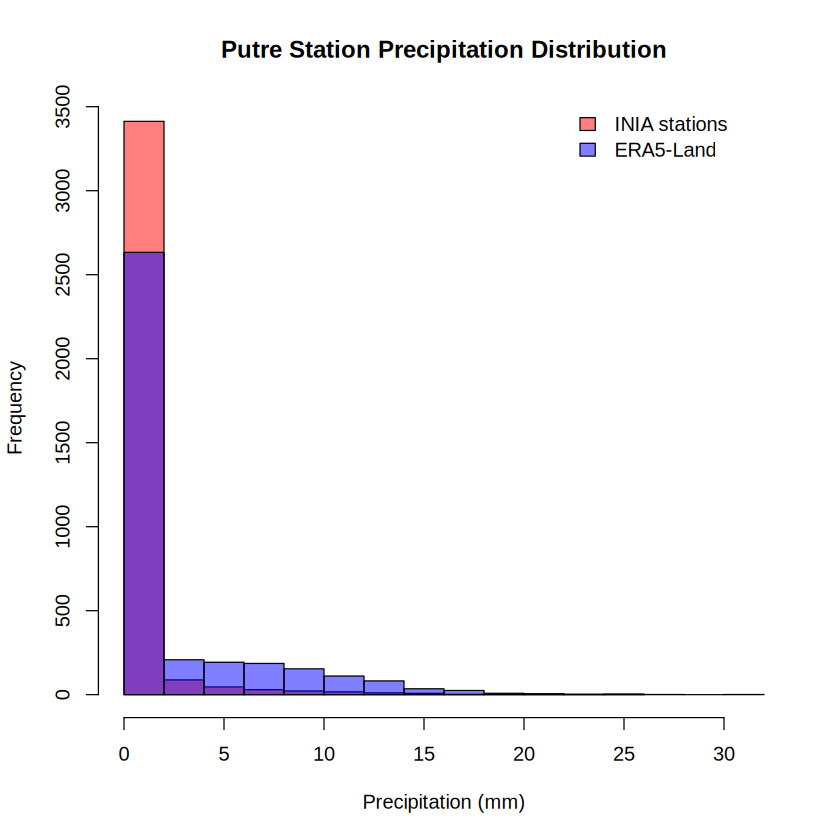

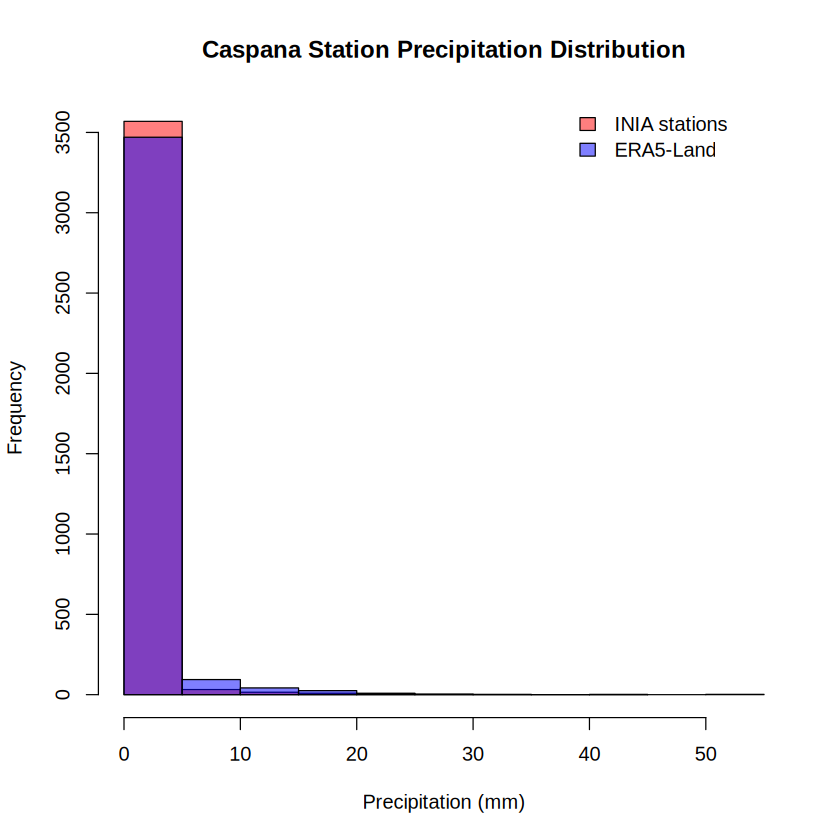

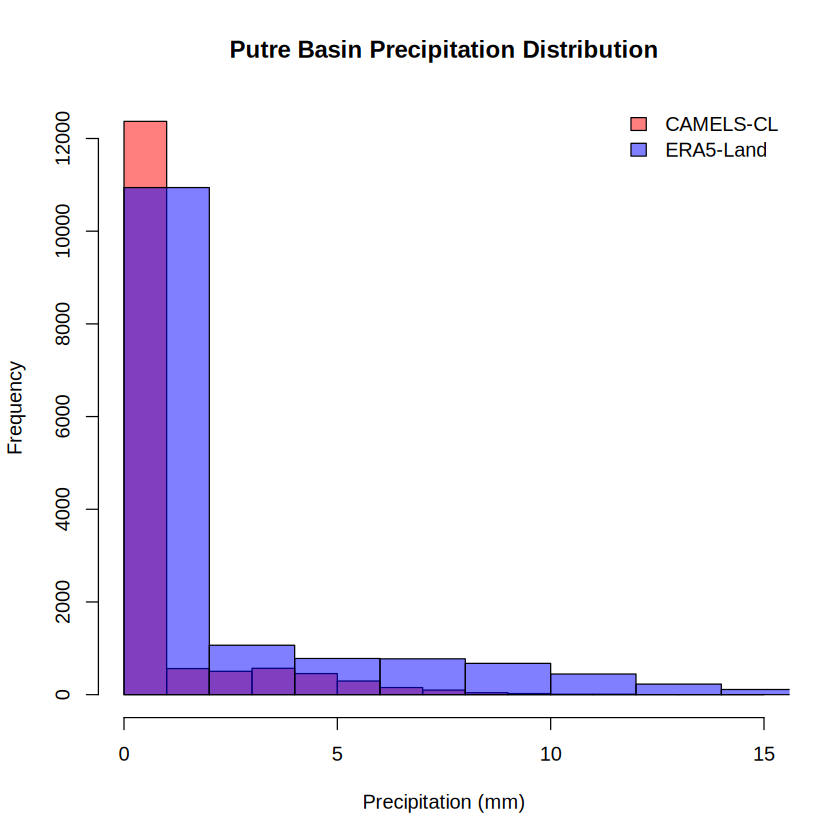

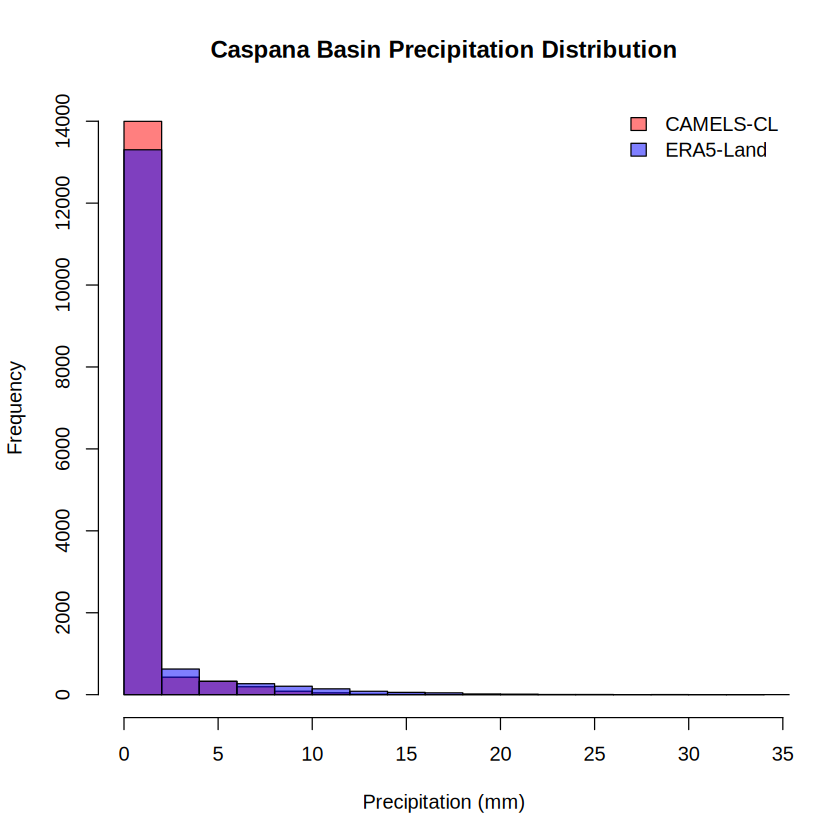

In [16]:

# Putre Station
h1 <- hist(df_inia_era5_putre$precipitation_mm_inia, xlab= "Precipitation (mm)", main= "Putre Station Precipitation Distribution", col=color1)
h2 <- hist(df_inia_era5_putre$precipitation_mm_era5, xlab= "", main= "", col=color2, add=TRUE)
legend("topright",
      legend = c("INIA stations", "ERA5-Land"),
      fill = c(color1, color2),
      bty = "n")

# Caspana Station
h3 <- hist(df_inia_era5_caspana$precipitation_mm_inia, xlab= "Precipitation (mm)", main= "Caspana Station Precipitation Distribution", col=color1)
h2 <- hist(df_inia_era5_caspana$precipitation_mm_era5, xlab= "", main= "", col=color2, add=TRUE)
legend("topright",
      legend = c("INIA stations", "ERA5-Land"),
      fill = c(color1, color2),
      bty = "n")

# Putre Basin
h1 <- hist(df_camels_era5_putre$precipitation_mm_camels, xlab= "Precipitation (mm)", main= "Putre Basin Precipitation Distribution", col=color1)
h2 <- hist(df_camels_era5_putre$precipitation_mm_era5, xlab= "", main= "", col=color2, add=TRUE)
legend("topright",
      legend = c("CAMELS-CL", "ERA5-Land"),
      fill = c(color1, color2),
      bty = "n")

# Caspana Basin
h3 <- hist(df_camels_era5_caspana$precipitation_mm_camels, xlab= "Precipitation (mm)", main= "Caspana Basin Precipitation Distribution", col=color1)
h2 <- hist(df_camels_era5_caspana$precipitation_mm_era5, xlab= "", main= "", col=color2, add=TRUE)
legend("topright",
      legend = c("CAMELS-CL", "ERA5-Land"),
      fill = c(color1, color2),
      bty = "n")

Temperature Distribution per station and basin




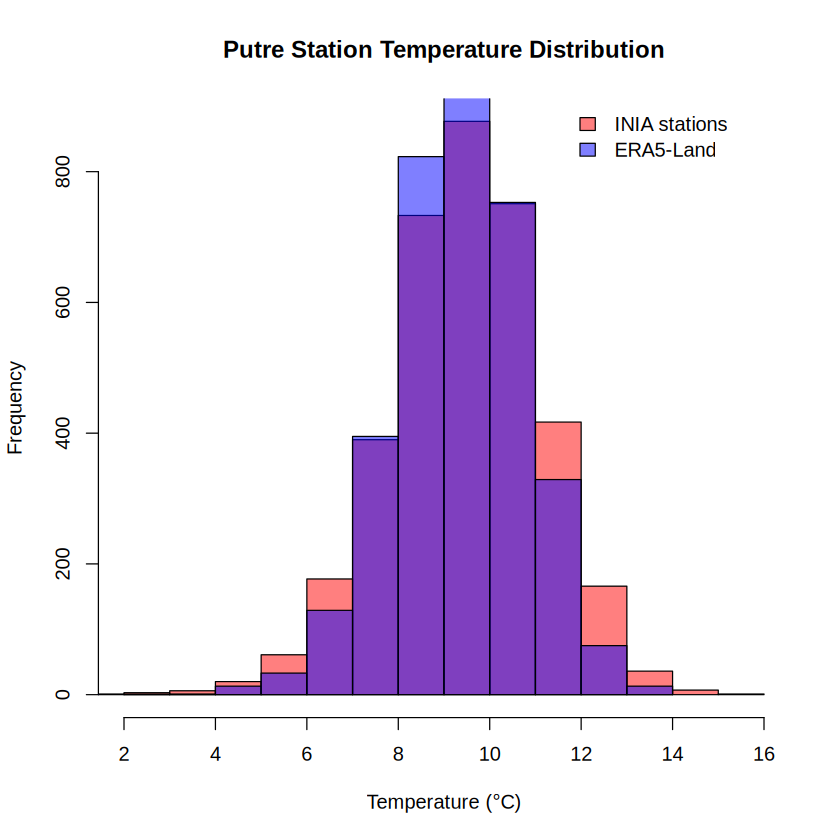

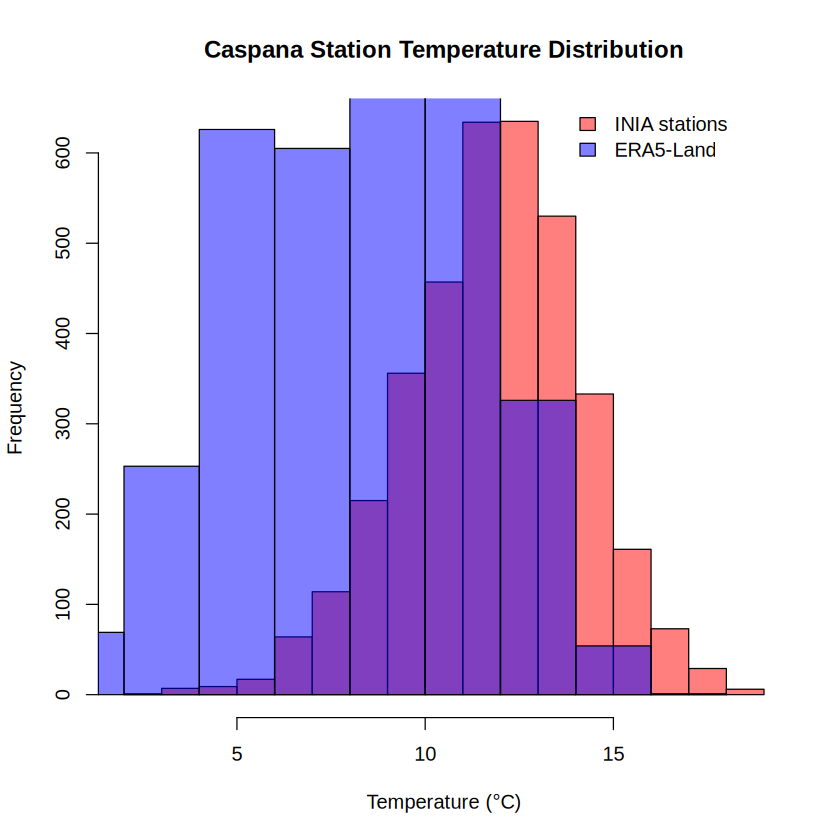

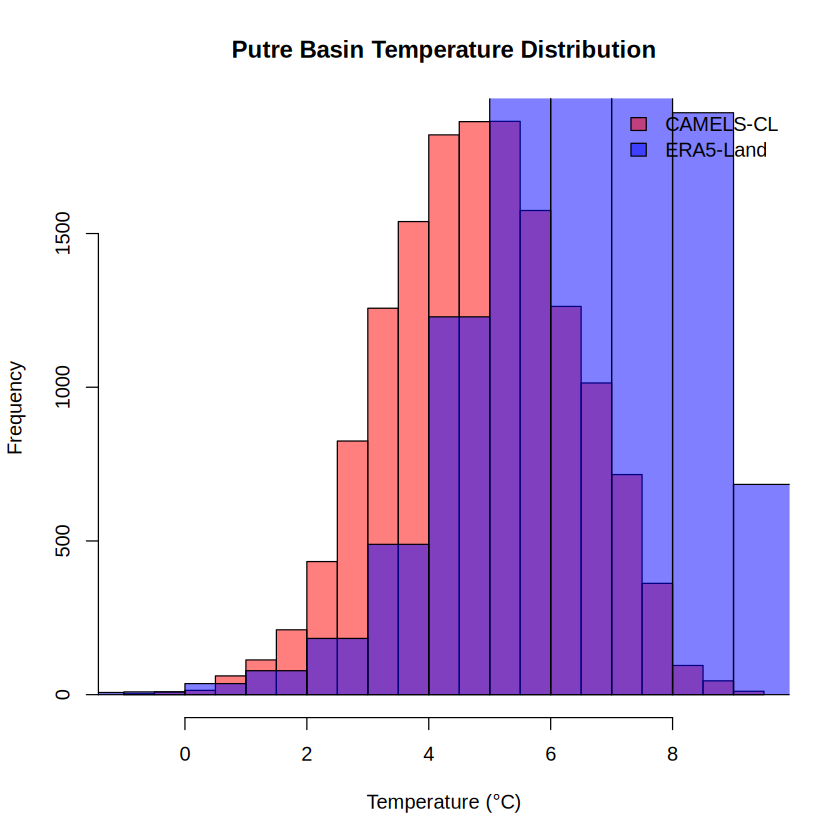

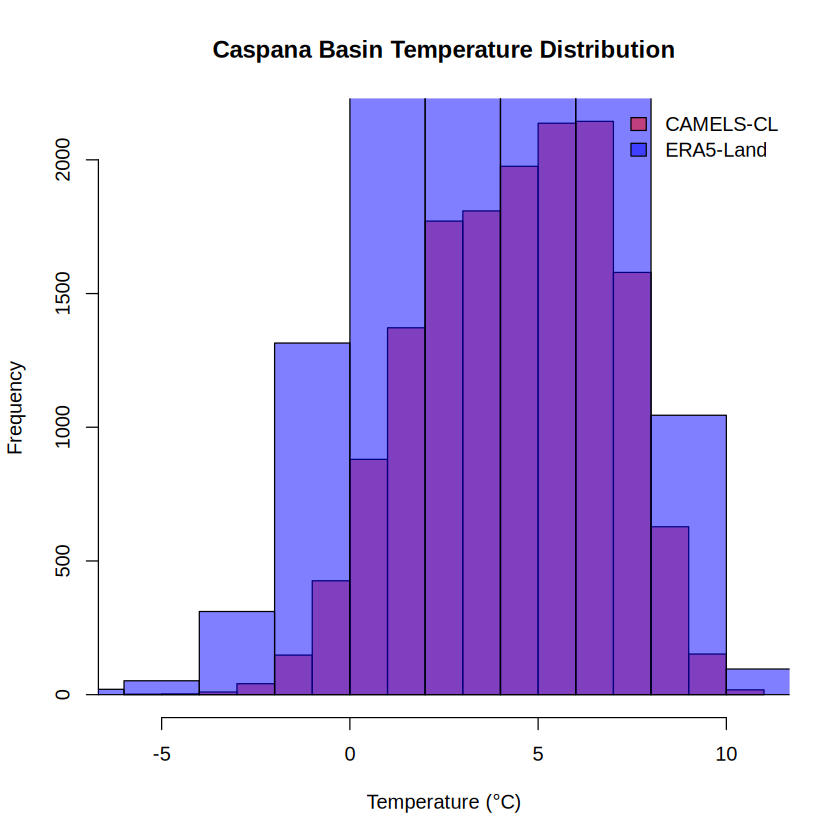

In [17]:
# Putre Station
h1 <- hist(df_inia_era5_putre$temperature_c_inia, xlab= "Temperature (°C)", main= "Putre Station Temperature Distribution", col=color1)
h2 <- hist(df_inia_era5_putre$temperature_c_era5, xlab= "", main= "", col=color2, add=TRUE)
legend("topright",
      legend = c("INIA stations", "ERA5-Land"),
      fill = c(color1, color2),
      bty = "n")

# Caspana Station
h3 <- hist(df_inia_era5_caspana$temperature_c_inia, xlab= "Temperature (°C)", main= "Caspana Station Temperature Distribution", col=color1)
h2 <- hist(df_inia_era5_caspana$temperature_c_era5, xlab= "", main= "", col=color2, add=TRUE)
legend("topright",
      legend = c("INIA stations", "ERA5-Land"),
      fill = c(color1, color2),
      bty = "n")

# Putre Basin
h1 <- hist(df_camels_era5_putre$temperature_c_camels, xlab= "Temperature (°C)", main= "Putre Basin Temperature Distribution", col=color1)
h2 <- hist(df_camels_era5_putre$temperature_c_era5, xlab= "", main= "", col=color2, add=TRUE)
legend("topright",
      legend = c("CAMELS-CL", "ERA5-Land"),
      fill = c(color1, color2),
      bty = "n")

# Caspana Basin
h3 <- hist(df_camels_era5_caspana$temperature_c_camels, xlab= "Temperature (°C)", main= "Caspana Basin Temperature Distribution", col=color1)
h2 <- hist(df_camels_era5_caspana$temperature_c_era5, xlab= "", main= "", col=color2, add=TRUE)
legend("topright",
      legend = c("CAMELS-CL", "ERA5-Land"),
      fill = c(color1, color2),
      bty = "n")
